# Lab 03: Developing a Tiny Transformer Language Model

In [1]:
%pip install datasets torch matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load the dataset

In [2]:
from datasets import load_dataset

dataset = load_dataset("roneneldan/TinyStories")
print(dataset)

C:\Users\oshan\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 2119719
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 21990
    })
})


In [3]:
# look at a few stories
for i in range(3):
    print("Story", i + 1)
    print(dataset["train"][i]["text"])
    print("-" * 50)

Story 1
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.
--------------------------------------------------
Story 2
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park wh

In [4]:
# length and structure of the first 1000 stories
sample = dataset["train"][:1000]["text"]

char_lengths = [len(story) for story in sample]
word_lengths = [len(story.split()) for story in sample]

print("Average characters per story:", sum(char_lengths) / len(char_lengths))
print("Shortest:", min(char_lengths), "Longest:", max(char_lengths))
print("Average words per story:", sum(word_lengths) / len(word_lengths))

# how the stories usually start
print("Start with 'Once upon a time':", sum(story.startswith("Once upon a time") for story in sample))
print("Start with 'One day':", sum(story.startswith("One day") for story in sample))
print("Have dialogue in quotes:", sum('"' in story for story in sample))

Average characters per story: 941.64
Shortest: 274 Longest: 4123
Average words per story: 183.801
Start with 'Once upon a time': 539
Start with 'One day': 41
Have dialogue in quotes: 531


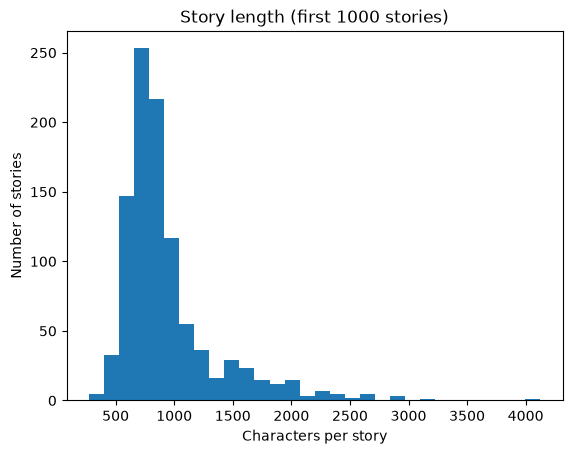

In [5]:
import matplotlib.pyplot as plt

plt.hist(char_lengths, bins=30)
plt.xlabel("Characters per story")
plt.ylabel("Number of stories")
plt.title("Story length (first 1000 stories)")
plt.show()

## 2. Preprocess the text

In [6]:
# the full train split has over 2 million stories, a small part is enough for a tiny model on a CPU
num_stories = 2000
stories = dataset["train"][:num_stories]["text"]
text = "\n\n".join(stories)

print("Stories used:", num_stories)
print("Total characters:", len(text))

Stories used: 2000
Total characters: 1704918


In [7]:
# character level tokenizer: every different character gets its own number
characters = sorted(set(text))
vocab_size = len(characters)

char_to_int = {ch: i for i, ch in enumerate(characters)}
int_to_char = {i: ch for i, ch in enumerate(characters)}

def encode(s):
    return [char_to_int[ch] for ch in s]

def decode(ids):
    return "".join(int_to_char[i] for i in ids)

print("Vocabulary size:", vocab_size)
print(characters)
print(encode("Once upon a time"))
print(decode(encode("Once upon a time")))

Vocabulary size: 80
['\n', ' ', '!', '"', '$', "'", ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '8', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '¦', 'â', 'œ', '˜', '“', '”', '€', '™']
[34, 59, 48, 50, 1, 66, 61, 60, 59, 1, 46, 1, 65, 54, 58, 50]
Once upon a time


## 3. Prepare the training data

In [8]:
import torch

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

data = torch.tensor(encode(text), dtype=torch.long)

# first 90% for training, last 10% to check the model on text it hasn't trained on
split_index = int(0.9 * len(data))
train_data = data[:split_index]
val_data = data[split_index:]

print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

Device: cpu
Training characters: 1534426
Validation characters: 170492


In [9]:
block_size = 64   # how many characters the model looks at, at once
batch_size = 32

# the target is the input moved one character to the right
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for t in range(8):
    print("input:", repr(decode(x[:t + 1].tolist())), "-> target:", repr(int_to_char[y[t].item()]))

input: 'O' -> target: 'n'
input: 'On' -> target: 'e'
input: 'One' -> target: ' '
input: 'One ' -> target: 'd'
input: 'One d' -> target: 'a'
input: 'One da' -> target: 'y'
input: 'One day' -> target: ','
input: 'One day,' -> target: ' '


In [10]:
def get_batch(split):
    d = train_data if split == "train" else val_data
    starts = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in starts])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Input shape:", xb.shape)
print("Target shape:", yb.shape)

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])
